In [ ]:

from google.colab import files
import pandas as pd

uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Saving online_retail_cleaned.csv to online_retail_cleaned.csv
Saving online_retail_basket_input.csv to online_retail_basket_input.csv
Dataset loaded successfully!
Shape: (779425, 17)


,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,total_revenue,year,month,month_name,quarter,day,day_of_week,hour,year_month
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4,2009,12,December,4,1,Tuesday,7,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009,12,December,4,1,Tuesday,7,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009,12,December,4,1,Tuesday,7,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8,2009,12,December,4,1,Tuesday,7,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0,2009,12,December,4,1,Tuesday,7,2009-12


In [2]:


print("DATASET VALIDATION REPORT")
print("=" * 40)

print("Rows and columns:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nColumn data types:")
print(df.dtypes)

print("\nNon-positive quantities:",
      (df["quantity"] <= 0).sum())

print("Non-positive unit prices:",
      (df["unit_price"] <= 0).sum())

revenue_diff = (
    df["total_revenue"] -
    df["quantity"] * df["unit_price"]
).abs()

print("\nMaximum revenue calculation difference:",
      revenue_diff.max())

df["invoice_date"] = pd.to_datetime(
    df["invoice_date"], errors="coerce"
)

print("Invalid invoice dates:",
      df["invoice_date"].isna().sum())

print("Date range:",
      df["invoice_date"].min(),
      "to",
      df["invoice_date"].max())

print("\nValidation complete.")


DATASET VALIDATION REPORT
Rows and columns: (779425, 17)
Missing values: 0
Duplicate rows: 0

Column data types:
invoice_no         int64
stock_code        object
description       object
quantity           int64
invoice_date      object
unit_price       float64
customer_id        int64
country           object
total_revenue    float64
year               int64
month              int64
month_name        object
quarter            int64
day                int64
day_of_week       object
hour               int64
year_month        object
dtype: object

Non-positive quantities: 0
Non-positive unit prices: 0

Maximum revenue calculation difference: 9.094947017729282e-13
Invalid invoice dates: 0
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00

Validation complete.


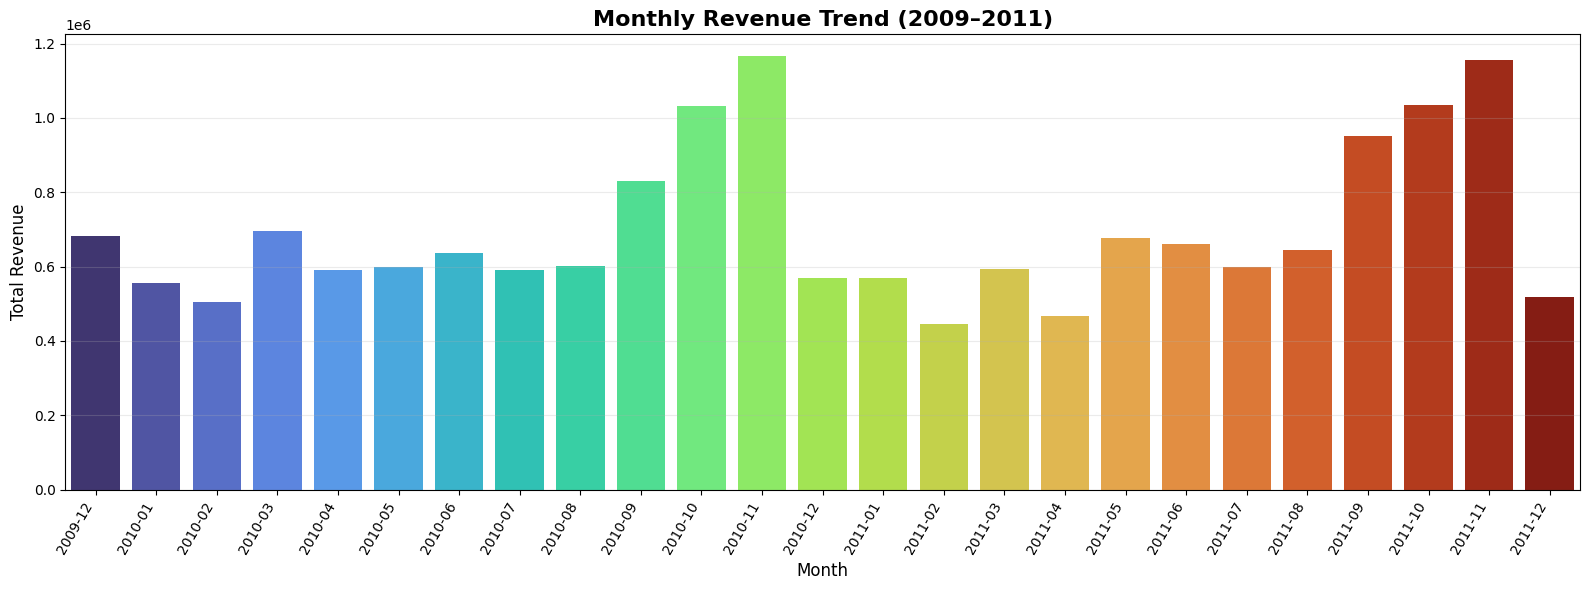

Top 5 months by revenue:


,year_month,total_revenue
0,2010-11,1166460.022
1,2011-11,1156205.610
2,2011-10,1035642.450
3,2010-10,1033112.010
4,2011-09,950690.202


In [3]:


import matplotlib.pyplot as plt
import seaborn as sns

monthly_revenue = (
    df.groupby("year_month", as_index=False)
      ["total_revenue"].sum()
      .sort_values("year_month")
)

plt.figure(figsize=(16, 6))

sns.barplot(
    data=monthly_revenue,
    x="year_month",
    y="total_revenue",
    hue="year_month",
    palette="turbo",
    legend=False
)

plt.title(
    "Monthly Revenue Trend (2009–2011)",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Revenue", fontsize=12)
plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("Top 5 months by revenue:")
display(
    monthly_revenue
    .nlargest(5, "total_revenue")
    .reset_index(drop=True)
)


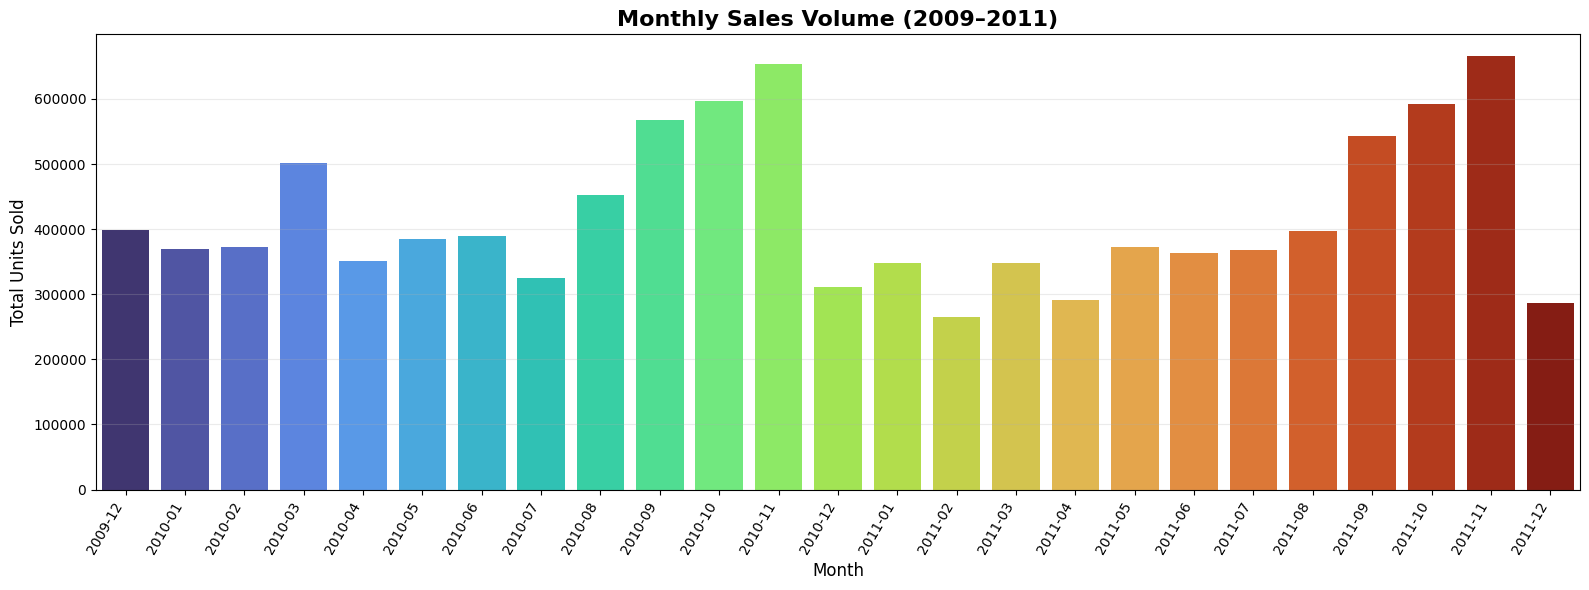

Top 5 months by units sold:


,year_month,quantity
0,2011-11,665923
1,2010-11,653068
2,2010-10,596432
3,2011-10,591543
4,2010-09,567153


In [4]:


monthly_units = (
    df.groupby("year_month", as_index=False)
      ["quantity"].sum()
      .sort_values("year_month")
)

plt.figure(figsize=(16, 6))

sns.barplot(
    data=monthly_units,
    x="year_month",
    y="quantity",
    hue="year_month",
    palette="turbo",
    legend=False
)

plt.title(
    "Monthly Sales Volume (2009–2011)",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Units Sold", fontsize=12)
plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("Top 5 months by units sold:")
display(
    monthly_units
    .nlargest(5, "quantity")
    .reset_index(drop=True)
)


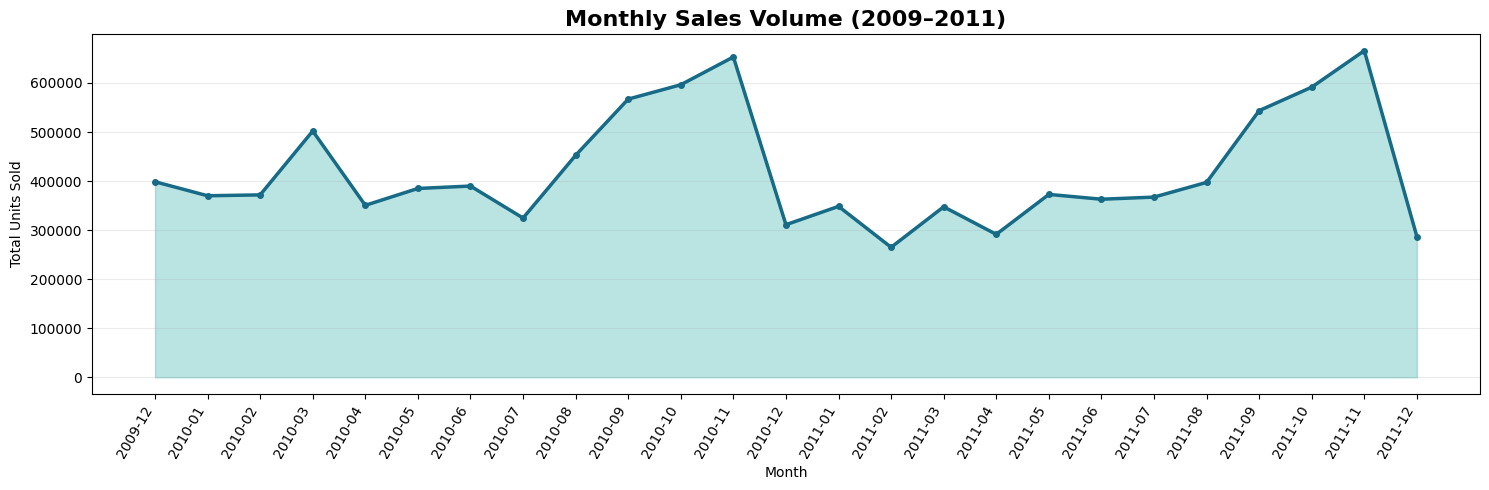

Top 5 months by units sold:


,year_month,quantity
0,2011-11,665923
1,2010-11,653068
2,2010-10,596432
3,2011-10,591543
4,2010-09,567153


In [5]:


monthly_units = (
    df.groupby("year_month", as_index=False)["quantity"]
      .sum()
      .sort_values("year_month")
)

plt.figure(figsize=(15, 5))

plt.fill_between(
    range(len(monthly_units)),
    monthly_units["quantity"],
    color="#38B2AC",
    alpha=0.35
)

plt.plot(
    range(len(monthly_units)),
    monthly_units["quantity"],
    color="#176B87",
    linewidth=2.5,
    marker="o",
    markersize=4
)

plt.title(
    "Monthly Sales Volume (2009–2011)",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Month")
plt.ylabel("Total Units Sold")
plt.xticks(
    range(len(monthly_units)),
    monthly_units["year_month"],
    rotation=60,
    ha="right"
)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("Top 5 months by units sold:")
display(
    monthly_units.nlargest(5, "quantity").reset_index(drop=True)
)


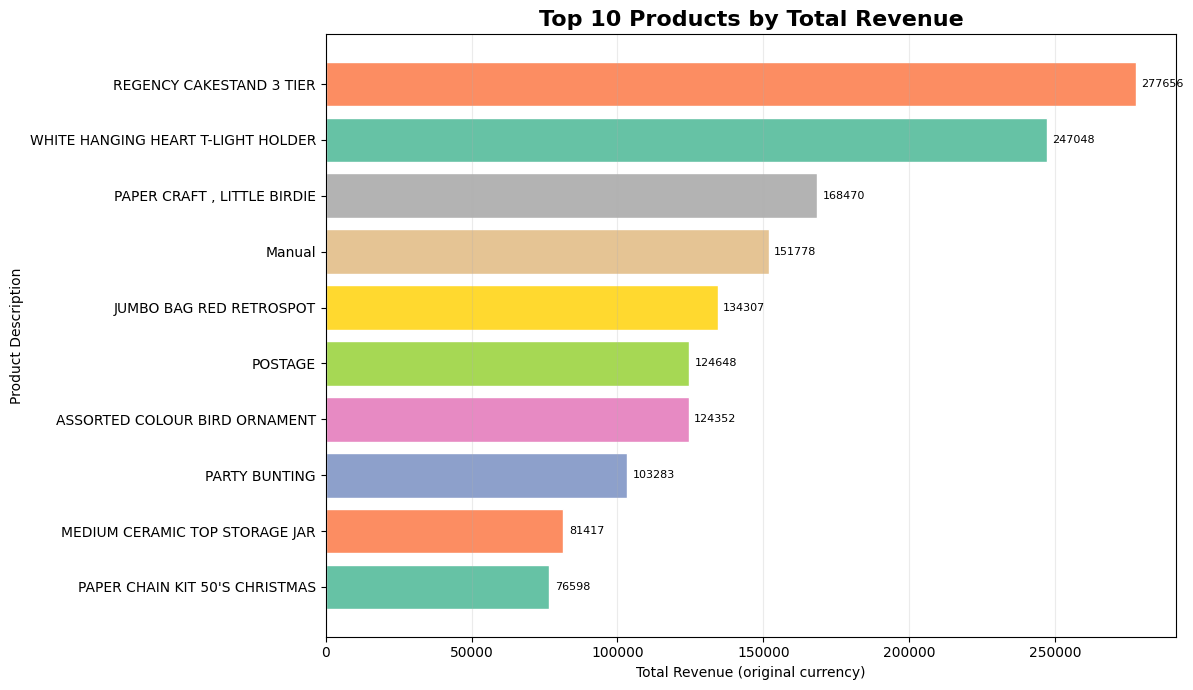

Top 10 products by revenue:


,total_revenue
description,
REGENCY CAKESTAND 3 TIER,277656.25
WHITE HANGING HEART T-LIGHT HOLDER,247048.01
"PAPER CRAFT , LITTLE BIRDIE",168469.60
Manual,151777.67
JUMBO BAG RED RETROSPOT,134307.44
POSTAGE,124648.04
ASSORTED COLOUR BIRD ORNAMENT,124351.86
PARTY BUNTING,103283.38
MEDIUM CERAMIC TOP STORAGE JAR,81416.73


In [6]:


top_products = (
    df.groupby("description")["total_revenue"]
      .sum()
      .nlargest(10)
      .sort_values(ascending=True)
)

colors = sns.color_palette("Set2", n_colors=len(top_products))

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top_products.index,
    top_products.values,
    color=colors,
    edgecolor="white"
)

ax.set_title(
    "Top 10 Products by Total Revenue",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Total Revenue (original currency)")
ax.set_ylabel("Product Description")
ax.grid(axis="x", alpha=0.25)
ax.bar_label(bars, fmt="%.0f", padding=4, fontsize=8)
plt.tight_layout()
plt.show()

print("Top 10 products by revenue:")
display(
    top_products.sort_values(ascending=False)
                .rename("total_revenue")
                .to_frame()
)


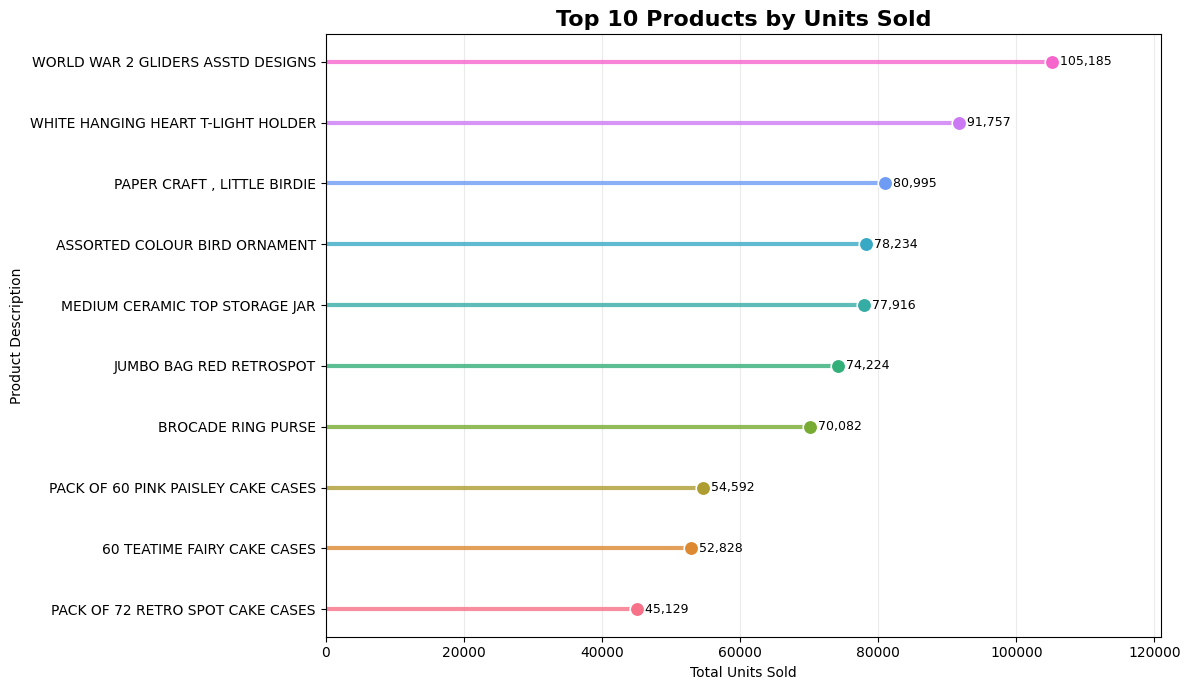

Top 10 products by units sold:


,total_quantity
description,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,105185
WHITE HANGING HEART T-LIGHT HOLDER,91757
"PAPER CRAFT , LITTLE BIRDIE",80995
ASSORTED COLOUR BIRD ORNAMENT,78234
MEDIUM CERAMIC TOP STORAGE JAR,77916
JUMBO BAG RED RETROSPOT,74224
BROCADE RING PURSE,70082
PACK OF 60 PINK PAISLEY CAKE CASES,54592
60 TEATIME FAIRY CAKE CASES,52828


In [8]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

top_quantity = (
    df.groupby("description")["quantity"]
      .sum()
      .nlargest(10)
      .sort_values(ascending=True)
)

colors = sns.color_palette("husl", len(top_quantity))
y = np.arange(len(top_quantity))

fig, ax = plt.subplots(figsize=(12, 7))

for i, (product, quantity) in enumerate(top_quantity.items()):
    ax.hlines(
        y=i, xmin=0, xmax=quantity,
        color=colors[i], linewidth=3, alpha=0.8
    )
    ax.scatter(
        quantity, i, color=colors[i],
        s=110, edgecolor="white", linewidth=1.2, zorder=3
    )
    ax.text(
        quantity, i, f"  {quantity:,.0f}",
        va="center", fontsize=9
    )

ax.set_yticks(y)
ax.set_yticklabels(top_quantity.index)
ax.set_title(
    "Top 10 Products by Units Sold",
    fontsize=16, fontweight="bold"
)
ax.set_xlabel("Total Units Sold")
ax.set_ylabel("Product Description")
ax.grid(axis="x", alpha=0.25)
ax.set_xlim(0, top_quantity.max() * 1.15)
plt.tight_layout()
plt.show()

print("Top 10 products by units sold:")
display(
    top_quantity.sort_values(ascending=False)
                .rename("total_quantity")
                .to_frame()
)


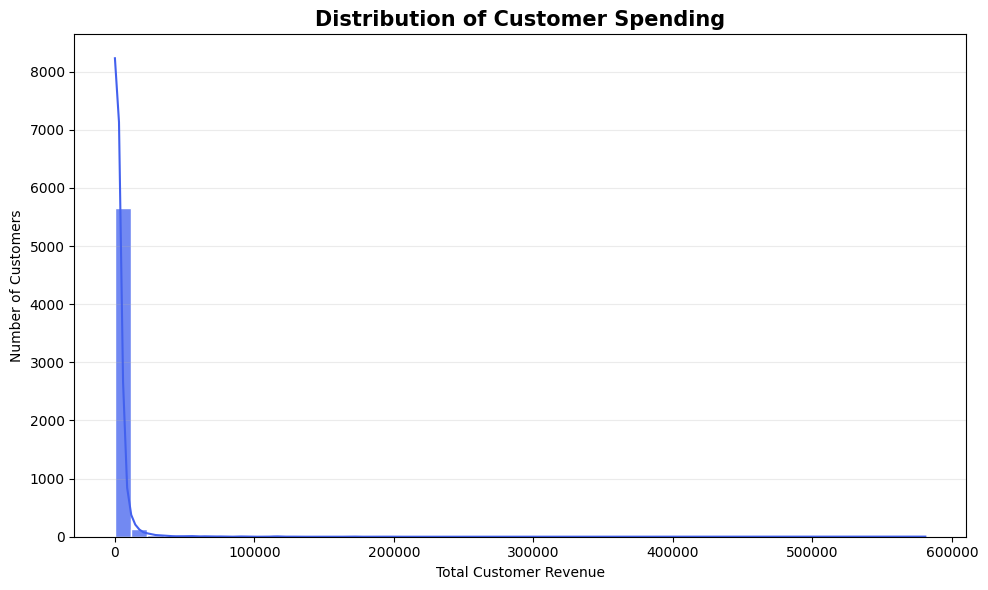

Number of customers: 5878
Mean spending: 2955.9
Median spending: 867.74

Top 10 customers by recorded revenue:


,total_revenue
customer_id,
18102,580987.04
14646,528602.52
14156,313437.62
14911,291420.81
17450,244784.25
13694,195640.69
17511,172132.87
16446,168472.50
16684,147142.77


In [13]:


customer_spending = (
    df.groupby("customer_id")["total_revenue"]
      .sum()
      .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    customer_spending,
    bins=50,
    kde=True,
    color="#4361EE",
    edgecolor="white",
    alpha=0.75,
    ax=ax
)

ax.set_title(
    "Distribution of Customer Spending",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Total Customer Revenue")
ax.set_ylabel("Number of Customers")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

print("Number of customers:", len(customer_spending))
print("Mean spending:", round(customer_spending.mean(), 2))
print("Median spending:", round(customer_spending.median(), 2))

print("\nTop 10 customers by recorded revenue:")
display(customer_spending.head(10).to_frame("total_revenue"))


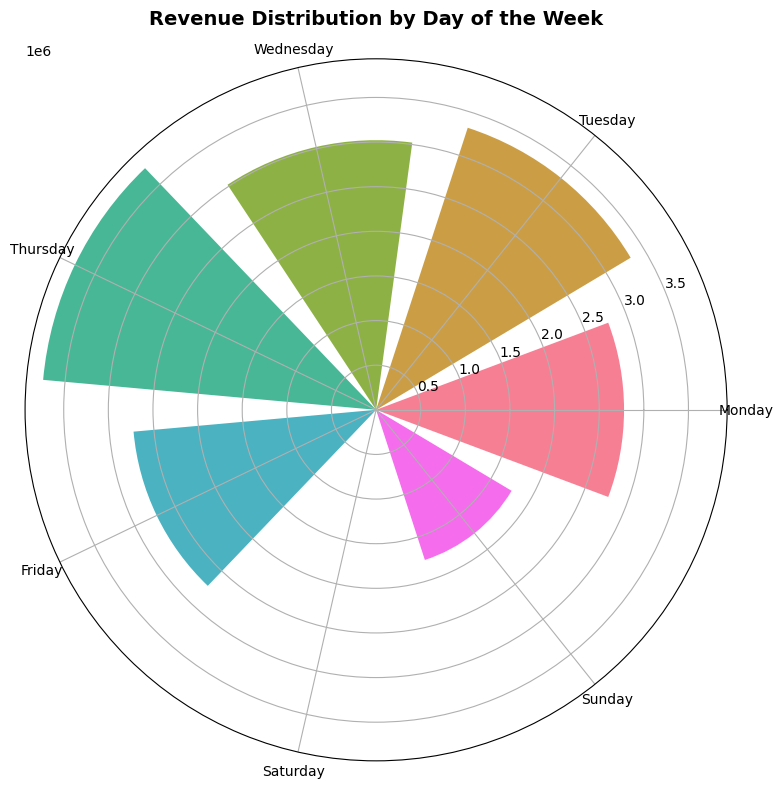

Revenue by day:


,total_revenue
day_of_week,
Thursday,3745783.432
Tuesday,3322830.142
Wednesday,3021043.853
Monday,2778201.566
Friday,2728473.173
Sunday,1768669.052
Saturday,9803.050


In [14]:


day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_revenue = (
    df.groupby("day_of_week")["total_revenue"]
      .sum()
      .reindex(day_order)
)

day_revenue = day_revenue.dropna()

angles = np.linspace(
    0, 2 * np.pi, len(day_revenue), endpoint=False
)

values = day_revenue.values
colors = sns.color_palette("husl", len(day_revenue))

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})

ax.bar(
    angles,
    values,
    width=2 * np.pi / len(day_revenue) * 0.8,
    color=colors,
    alpha=0.9
)

ax.set_xticks(angles)
ax.set_xticklabels(day_revenue.index)
ax.set_title(
    "Revenue Distribution by Day of the Week",
    fontsize=14,
    fontweight="bold",
    pad=25
)

plt.tight_layout()
plt.show()

print("Revenue by day:")
display(day_revenue.sort_values(ascending=False).to_frame("total_revenue"))
